# Seasonal Agriculture Performance Analysis
### Major Project — VOIS AICTE Batch1 2026-2027

**Name:** _[Your Name Here]_
**Roll No / Reg No:** _[Your Roll Number Here]_
**Domain:** Data Analytics

---

## 1. Introduction

Farming in India (and most places) doesn't behave the same way all year round. The same field can give a great yield in one season and a mediocre one in the next, simply because rainfall, temperature, humidity and the crop being grown are all different across seasons.

This dataset has 4,000 farm records spread across **three seasons — Kharif, Rabi and Zaid** — and covers everything from soil and weather conditions to fertilizer/water usage to the final economics (cost, revenue, profit) of each farm.

The goal of this notebook is simple: **figure out how agricultural performance actually changes from season to season**, and back it up with numbers, charts and a bit of statistics rather than just guessing.

## 2. Objective

- Explore and clean the dataset properly before drawing any conclusions.
- Compare environmental conditions, resource usage, yield/production and profitability across the three seasons.
- Look for relationships between conditions (rainfall, water use, etc.) and outcomes (yield, profit).
- Check whether the seasonal patterns hold across different states/regions, or if they vary.
- Use a couple of statistical tests to confirm the differences we see are actually meaningful, not just random noise.
- Wrap up with insights and recommendations that could help with seasonal agricultural planning.


## 3. Importing the libraries we'll need

In [1]:
# Standard data analysis stack
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# For the significance tests later
from scipy import stats

# Just makes the charts look a little nicer and consistent
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

pd.set_option('display.max_columns', None)


## 4. Loading the Dataset

Let's load the CSV and take a first look — shape, column names, data types, and a preview of a few rows.

In [2]:
df = pd.read_csv("seasonal_agriculture_performance_dataset.csv")
print("Shape of the dataset:", df.shape)
df.head()


Shape of the dataset: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,7.14,32.8,75.8,61.3,91.0,Drip,242.7,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,5.20,32.0,82.1,35.4,121.8,Flood,271.4,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,5.82,8.1,118.5,51.5,117.9,Drip,162.6,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,5.98,23.7,138.6,55.6,115.5,Rainfed,182.2,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,6.90,29.3,124.1,69.0,121.4,Flood,244.9,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [4]:
# Quick statistical summary of all the numeric columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,4000.0,7.888265,4.223764,0.500,4.260,7.8950,11.65000,15.00
Rainfall_mm,3952.0,601.152657,288.925025,80.000,370.200,582.0000,834.95000,1395.20
Avg_Temperature_C,4000.0,26.818900,3.818180,16.200,23.900,26.9000,29.60000,39.70
Humidity_pct,4000.0,63.210500,11.960834,25.000,54.775,63.0000,71.90000,95.00
Sunlight_Hours_Day,4000.0,7.323050,1.121186,3.500,6.600,7.3000,8.10000,11.00
Soil_pH,4000.0,6.701010,0.641461,5.200,6.260,6.6900,7.14000,8.40
Soil_Moisture_pct,3960.0,26.508232,6.712484,8.000,21.700,26.4000,31.30000,47.00
Nitrogen_kg_ha,4000.0,120.250825,31.216452,40.000,98.500,120.1000,141.22500,220.00
Phosphorus_kg_ha,4000.0,57.781850,17.015074,15.000,46.200,57.5000,69.40000,120.00
Potassium_kg_ha,4000.0,104.760050,27.742681,30.000,86.200,105.1000,123.60000,200.00


## 5. Data Cleaning & Preparation

Before doing any real analysis, it's important to check the dataset for missing values, duplicate rows, and anything that looks off (e.g. negative areas, impossible percentages, etc). Skipping this step is basically the fastest way to end up with wrong conclusions later.

In [5]:
# Checking for missing values
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
print(missing)


Columns with missing values:
Rainfall_mm          48
Soil_Moisture_pct    40
Yield_Tonnes_Ha      32
dtype: int64


In [6]:
# Checking for duplicate rows / duplicate Farm IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Farm IDs:", df['Farm_ID'].duplicated().sum())


Duplicate rows: 0
Duplicate Farm IDs: 0


Only three columns have missing values — `Rainfall_mm`, `Soil_Moisture_pct` and `Yield_Tonnes_Ha` — and the number of missing entries is small compared to the 4,000 total rows (about 1%). Since this is weather/yield data that naturally differs by season and crop, filling missing values with the **overall** median wouldn't be very accurate. Instead, we fill each missing value with the **median of that same Season + Crop group**, which keeps the imputation realistic. If a group happens to have no data at all for that combination, we fall back to the overall column median.

In [7]:
for col in ['Rainfall_mm', 'Soil_Moisture_pct', 'Yield_Tonnes_Ha']:
    df[col] = df.groupby(['Season', 'Crop'])[col].transform(lambda x: x.fillna(x.median()))
    # fallback in case a Season+Crop group had zero non-null values
    df[col] = df[col].fillna(df[col].median())

print("Missing values remaining:")
print(df.isnull().sum().sum())


Missing values remaining:
0


Next, let's sanity-check a few numeric columns for values that shouldn't logically exist — negative areas, yields, water usage, or percentages outside 0-100.

In [8]:
checks = {
    'Farm_Area_Hectares': (df['Farm_Area_Hectares'] <= 0).sum(),
    'Yield_Tonnes_Ha (negative)': (df['Yield_Tonnes_Ha'] < 0).sum(),
    'Production_Tonnes (negative)': (df['Production_Tonnes'] < 0).sum(),
    'Water_Used_m3 (negative)': (df['Water_Used_m3'] < 0).sum(),
    'Humidity_pct out of 0-100': ((df['Humidity_pct'] < 0) | (df['Humidity_pct'] > 100)).sum(),
    'Soil_Moisture_pct out of 0-100': ((df['Soil_Moisture_pct'] < 0) | (df['Soil_Moisture_pct'] > 100)).sum(),
}
for k, v in checks.items():
    print(f"{k}: {v} problematic rows")


Farm_Area_Hectares: 0 problematic rows
Yield_Tonnes_Ha (negative): 0 problematic rows
Production_Tonnes (negative): 0 problematic rows
Water_Used_m3 (negative): 0 problematic rows
Humidity_pct out of 0-100: 0 problematic rows
Soil_Moisture_pct out of 0-100: 0 problematic rows


No impossible values found there, which is good. One thing worth flagging though: some rows have **negative profit** (`Profit_INR`), which at first glance looks like "bad data" — but it's actually realistic. A farm can genuinely make a loss if costs exceed revenue in a bad season. So we keep those rows; they're valid data points, not errors.

Let's also do a quick outlier check on `Yield_Tonnes_Ha` using the IQR method, just to understand the spread rather than to blindly remove points.

In [9]:
Q1 = df['Yield_Tonnes_Ha'].quantile(0.25)
Q3 = df['Yield_Tonnes_Ha'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Yield_Tonnes_Ha'] < lower) | (df['Yield_Tonnes_Ha'] > upper)]
print(f"Yield range considered 'normal' by IQR rule: {lower:.2f} to {upper:.2f} t/ha")
print(f"Number of outlier rows: {len(outliers)} out of {len(df)} ({len(outliers)/len(df)*100:.1f}%)")


Yield range considered 'normal' by IQR rule: -1.63 to 5.52 t/ha
Number of outlier rows: 304 out of 4000 (7.6%)


There are a handful of unusually high yield values (likely Sugarcane, which naturally has a much higher yield per hectare than crops like Wheat or Pulses — sugarcane is measured in tens of tonnes/ha, so this isn't a data error, it's a genuine crop-type effect). We'll keep these rows but keep this in mind while interpreting yield charts, and where needed we'll look at crops separately.

Dataset is clean now — no duplicates, no missing values, no impossible readings. Let's move on to actually exploring it.

## 6. Getting a Feel for the Data

Before comparing seasons, let's just look at what's actually in the dataset — how many farms per season, which crops are most common, and which states are represented.

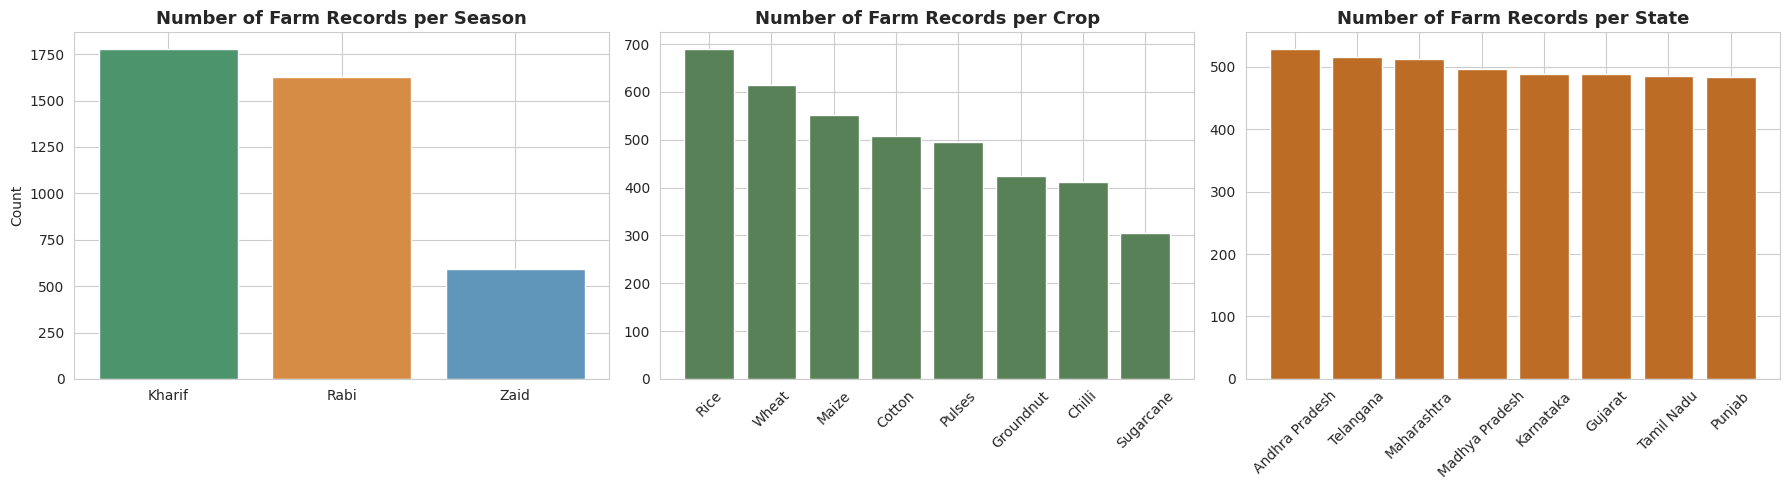

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

season_counts = df['Season'].value_counts()
axes[0].bar(season_counts.index, season_counts.values, color=['#4C956C', '#D68C45', '#6096BA'])
axes[0].set_title('Number of Farm Records per Season')
axes[0].set_ylabel('Count')

crop_counts = df['Crop'].value_counts()
axes[1].bar(crop_counts.index, crop_counts.values, color='#588157')
axes[1].set_title('Number of Farm Records per Crop')
axes[1].tick_params(axis='x', rotation=45)

state_counts = df['State'].value_counts()
axes[2].bar(state_counts.index, state_counts.values, color='#BC6C25')
axes[2].set_title('Number of Farm Records per State')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**Kharif** has the most records (1,779), followed by **Rabi** (1,627) and then **Zaid** (594) — which actually matches real agricultural practice, since Zaid is a short in-between summer season and fewer crops are grown then. Crops and states both look fairly evenly spread, so no single crop or state should be silently skewing our seasonal comparisons.

Let's also check which crops are grown in which seasons — this matters because comparing one season to another partly just reflects which crops happen to be grown in that season.


In [11]:
crop_season = pd.crosstab(df['Crop'], df['Season'])
crop_season


Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,185,163,64
Cotton,215,201,92
Groundnut,193,177,54
Maize,234,233,84
Pulses,221,213,62
Rice,314,274,102
Sugarcane,125,129,51
Wheat,292,237,85


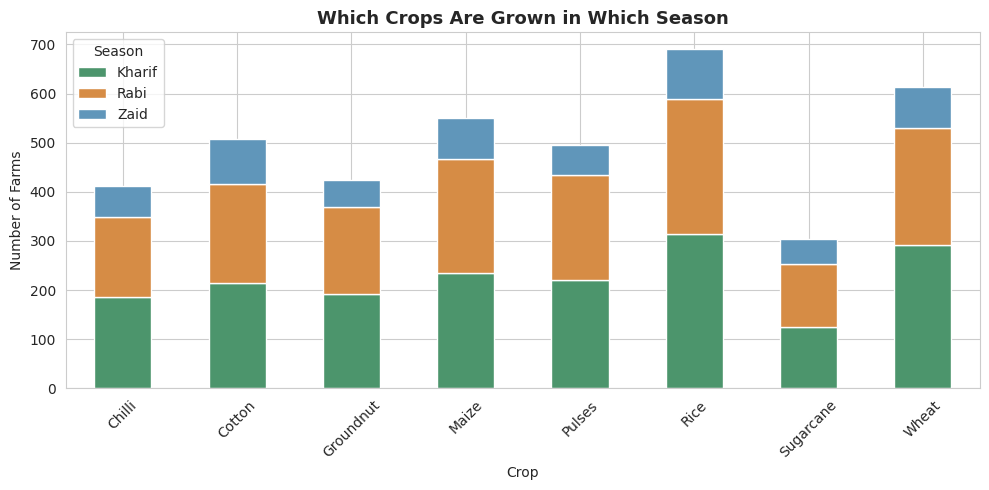

In [12]:
crop_season.plot(kind='bar', stacked=True, figsize=(10, 5),
                  color=['#4C956C', '#D68C45', '#6096BA'])
plt.title('Which Crops Are Grown in Which Season')
plt.ylabel('Number of Farms')
plt.xlabel('Crop')
plt.legend(title='Season')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


As expected, crop mix isn't identical across seasons — e.g. Rice and Sugarcane lean towards Kharif/Rabi while Zaid has a lighter, more limited crop spread. Good to know as we read the rest of the charts.

## 7. How Environmental Conditions Differ Across Seasons

This is the most basic seasonal question — does rainfall, temperature, humidity and sunlight actually differ meaningfully between Kharif, Rabi and Zaid in this data?

In [13]:
env_cols = ['Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day']

season_env = df.groupby('Season')[env_cols].mean().round(2)
season_env


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day
Season,,,,
Kharif,852.10,28.45,71.81,6.79
Rabi,435.95,23.49,57.89,7.59
Zaid,299.16,31.04,52.01,8.18


/tmp/ipykernel_543/1782794127.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y=col, ax=axes[i],
/tmp/ipykernel_543/1782794127.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y=col, ax=axes[i],
/tmp/ipykernel_543/1782794127.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y=col, ax=axes[i],
/tmp/ipykernel_543/1782794127.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set

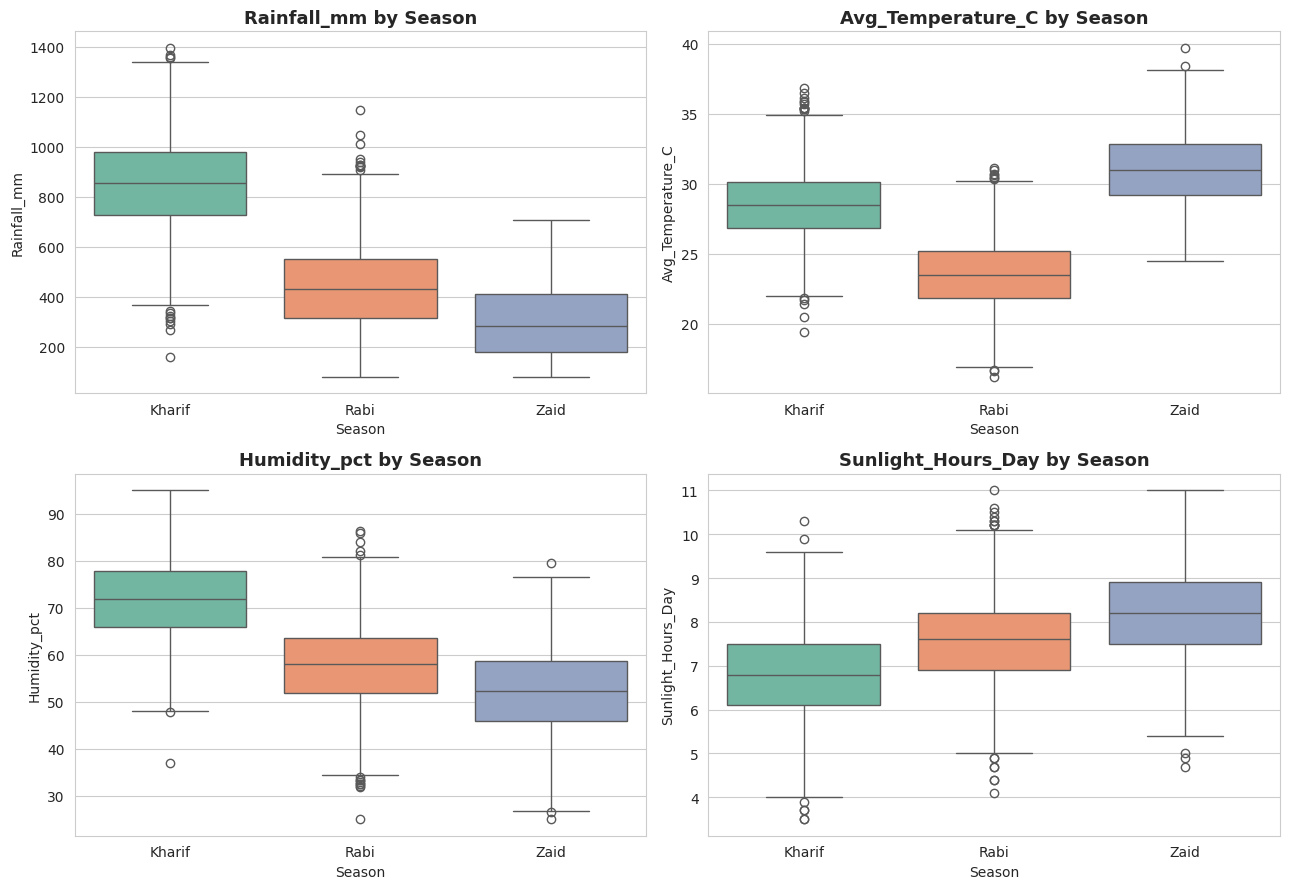

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(env_cols):
    sns.boxplot(data=df, x='Season', y=col, ax=axes[i],
                order=['Kharif', 'Rabi', 'Zaid'], palette='Set2')
    axes[i].set_title(f'{col} by Season')

plt.tight_layout()
plt.show()


A few clear patterns show up here:

- **Rainfall** is by far the highest during **Kharif** (the monsoon season) and drops sharply for Rabi and Zaid — which lines up exactly with how the Indian monsoon calendar works in real life.
- **Temperature** is highest in **Zaid** (the summer season) and comparatively cooler in Rabi (winter).
- **Humidity** follows rainfall fairly closely — highest in Kharif.
- **Sunlight hours** are a bit higher in Zaid, which also makes sense for the summer months.

So the dataset's seasonal weather logic is internally consistent, which is a good sign for trusting the rest of the analysis.

## 8. Resource Usage Across Seasons

Now let's look at how farmers are using resources — fertilizer, pesticide, and water — and how irrigation method choice shifts by season.

In [15]:
resource_cols = ['Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3']

season_resources = df.groupby('Season')[resource_cols].mean().round(2)
season_resources


,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_Used_m3,Water_Efficiency_t_per_1000m3
Season,,,,
Kharif,187.08,5.08,6102.20,5.89
Rabi,185.41,5.02,5846.99,5.19
Zaid,184.64,5.17,6419.89,4.41


/tmp/ipykernel_543/1870907345.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Season', y='Fertilizer_kg_ha', order=['Kharif','Rabi','Zaid'],
/tmp/ipykernel_543/1870907345.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Season', y='Water_Used_m3', order=['Kharif','Rabi','Zaid'],


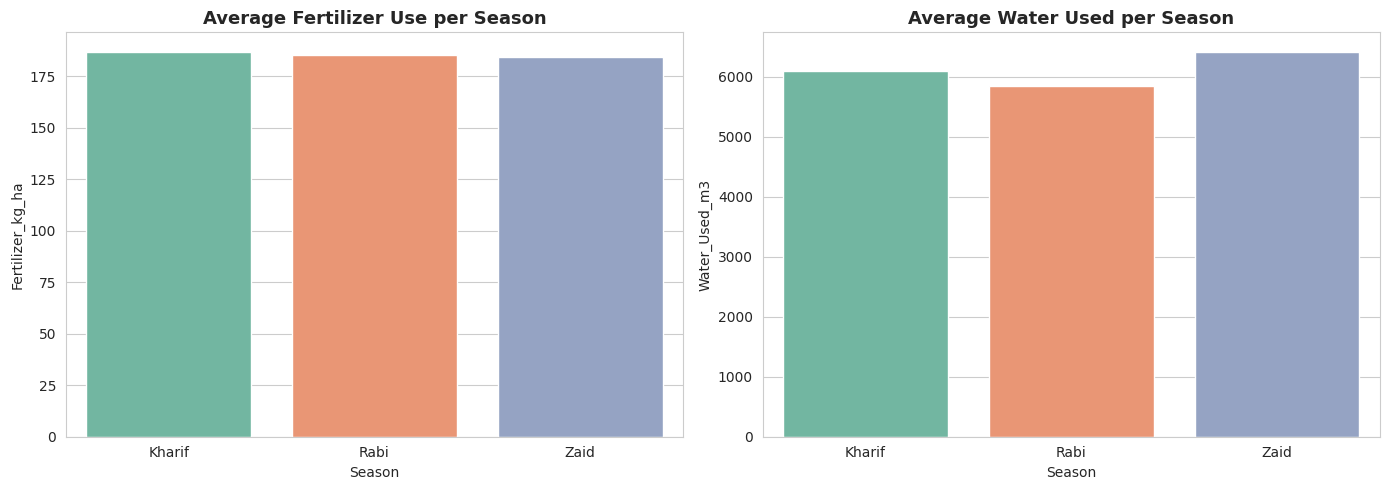

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Season', y='Fertilizer_kg_ha', order=['Kharif','Rabi','Zaid'],
            ax=axes[0], palette='Set2', errorbar=None)
axes[0].set_title('Average Fertilizer Use per Season')

sns.barplot(data=df, x='Season', y='Water_Used_m3', order=['Kharif','Rabi','Zaid'],
            ax=axes[1], palette='Set2', errorbar=None)
axes[1].set_title('Average Water Used per Season')

plt.tight_layout()
plt.show()


In [17]:
irrigation_season = pd.crosstab(df['Season'], df['Irrigation_Method'], normalize='index') * 100
irrigation_season = irrigation_season.round(1)
irrigation_season


Irrigation_Method,Drip,Flood,Rainfed,Sprinkler
Season,,,,
Kharif,22.8,33.2,26.0,18.0
Rabi,22.7,32.3,26.9,18.0
Zaid,23.6,32.7,23.6,20.2


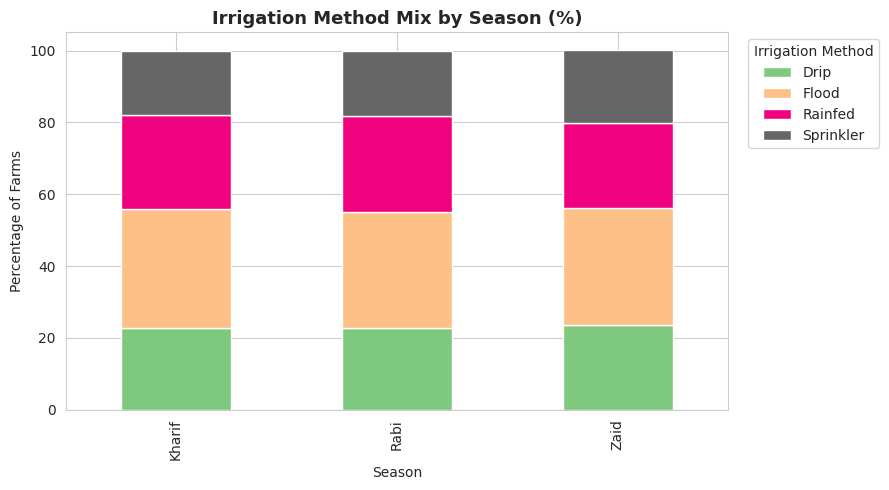

In [18]:
irrigation_season.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='Accent')
plt.title('Irrigation Method Mix by Season (%)')
plt.ylabel('Percentage of Farms')
plt.legend(title='Irrigation Method', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


Water usage is noticeably higher in **Zaid**, which makes sense — it's the hottest, driest season, so crops need extra irrigation to compensate for the lack of rainfall. Rainfed irrigation is more common in Kharif (since the monsoon does a lot of the work naturally), while Zaid leans more on Drip/Sprinkler methods that use water more deliberately. Fertilizer usage doesn't swing as dramatically across seasons — it looks more crop-dependent than season-dependent.

## 9. Yield & Production Across Seasons

This is one of the most important comparisons — how much are farms actually producing in each season?

/tmp/ipykernel_543/678684213.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y='Yield_Tonnes_Ha', order=['Kharif','Rabi','Zaid'],
/tmp/ipykernel_543/678684213.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y='Production_Tonnes', order=['Kharif','Rabi','Zaid'],


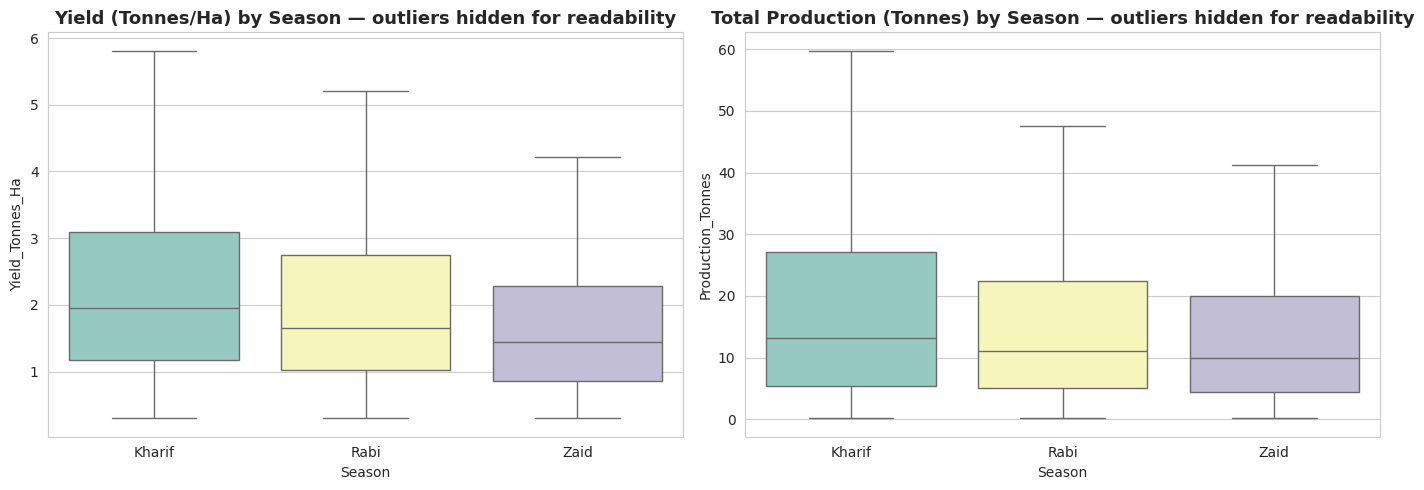

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Season', y='Yield_Tonnes_Ha', order=['Kharif','Rabi','Zaid'],
            ax=axes[0], palette='Set3', showfliers=False)
axes[0].set_title('Yield (Tonnes/Ha) by Season — outliers hidden for readability')

sns.boxplot(data=df, x='Season', y='Production_Tonnes', order=['Kharif','Rabi','Zaid'],
            ax=axes[1], palette='Set3', showfliers=False)
axes[1].set_title('Total Production (Tonnes) by Season — outliers hidden for readability')

plt.tight_layout()
plt.show()


In [20]:
df.groupby('Season')[['Yield_Tonnes_Ha', 'Production_Tonnes']].agg(['mean', 'median']).round(2)


Yield_Tonnes_Ha        Production_Tonnes       
                  mean median              mean median
Season                                                
Kharif            5.63   1.95             46.31  13.24
Rabi              5.09   1.66             41.49  11.08
Zaid              4.64   1.45             38.89   9.97

Since yield varies a LOT by crop type (Sugarcane naturally yields far more tonnes/ha than Pulses, regardless of season), it's worth breaking this down by crop as well, so we're not just comparing which season happens to have more sugarcane farms.


In [21]:
pivot_yield = df.pivot_table(values='Yield_Tonnes_Ha', index='Crop', columns='Season', aggfunc='mean').round(2)
pivot_yield


Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,1.73,1.46,1.18
Cotton,1.37,1.19,0.95
Groundnut,1.48,1.22,1.04
Maize,2.97,2.62,2.30
Pulses,1.04,0.87,0.65
Rice,2.71,2.33,1.90
Sugarcane,53.46,43.96,38.42
Wheat,2.26,2.06,1.75


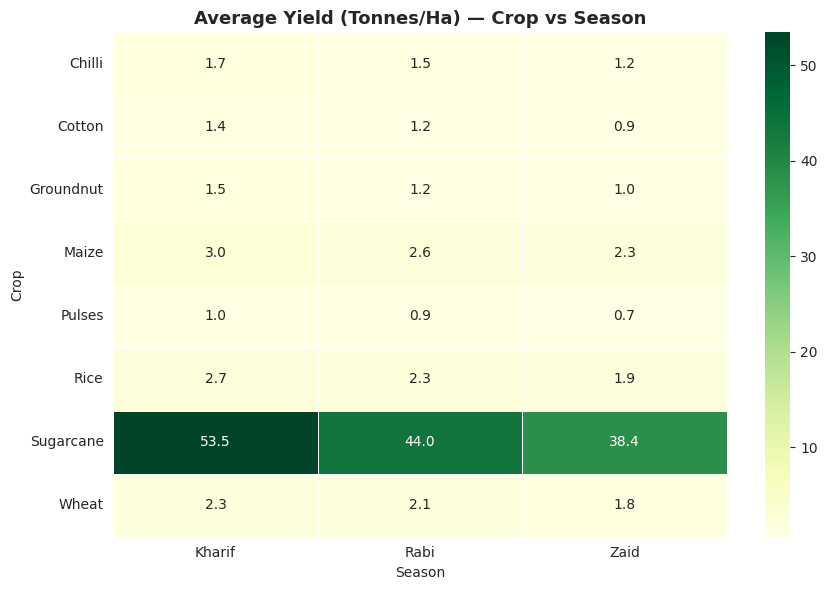

In [22]:
plt.figure(figsize=(9, 6))
sns.heatmap(pivot_yield, annot=True, fmt='.1f', cmap='YlGn', linewidths=0.5)
plt.title('Average Yield (Tonnes/Ha) — Crop vs Season')
plt.tight_layout()
plt.show()


Looking at yield crop-by-crop is much more informative than the overall season average — for most crops here, **Kharif and Rabi give a noticeably better yield than Zaid**, which fits with Zaid being a shorter, hotter, water-stressed season that's typically only used for a limited set of quick-growing crops.

## 10. Economic Performance Across Seasons

Good yield doesn't automatically mean good profit — cost of inputs and market price both matter. Let's check cost, revenue and profit season-wise.

In [23]:
econ_cols = ['Total_Cost_INR', 'Revenue_INR', 'Profit_INR']
season_econ = df.groupby('Season')[econ_cols].mean().round(0)
season_econ


,Total_Cost_INR,Revenue_INR,Profit_INR
Season,,,
Kharif,531804.0,710719.0,178915.0
Rabi,513837.0,601526.0,87689.0
Zaid,543977.0,519172.0,-24805.0


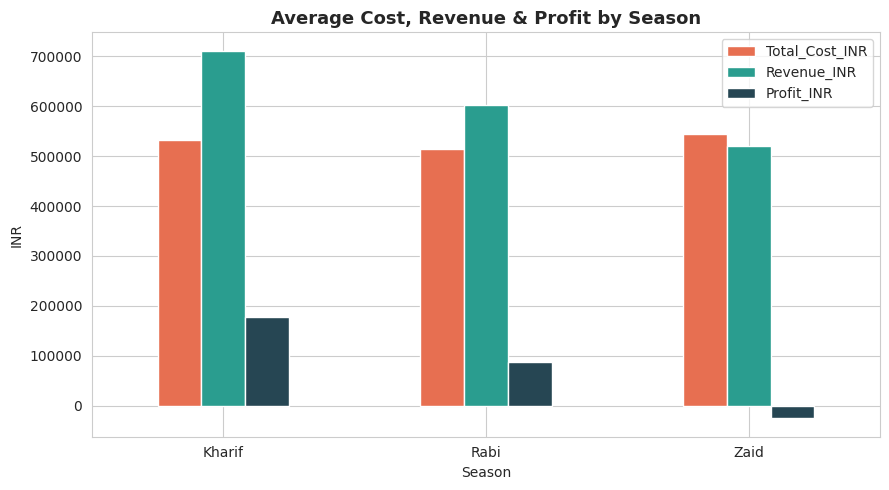

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
season_econ.plot(kind='bar', ax=ax, color=['#E76F51', '#2A9D8F', '#264653'])
plt.title('Average Cost, Revenue & Profit by Season')
plt.ylabel('INR')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [25]:
# What fraction of farms actually run at a loss, per season?
loss_pct = df.groupby('Season').apply(lambda g: (g['Profit_INR'] < 0).mean() * 100).round(1)
loss_pct.name = '% of farms running at a loss'
loss_pct


Season
Kharif    42.2
Rabi      51.1
Zaid      64.5
Name: % of farms running at a loss, dtype: float64

This is a genuinely useful finding: it's not just about which season produces more — it's about which season is more **financially reliable**. Comparing the average profit alongside the percentage of loss-making farms per season gives a fuller economic picture than yield numbers alone.

## 11. Correlation Analysis — What's Actually Related to What?

Let's step back from season-by-season comparisons for a moment and check which numeric variables are correlated with each other across the whole dataset — particularly, what's associated with higher yield and higher profit.

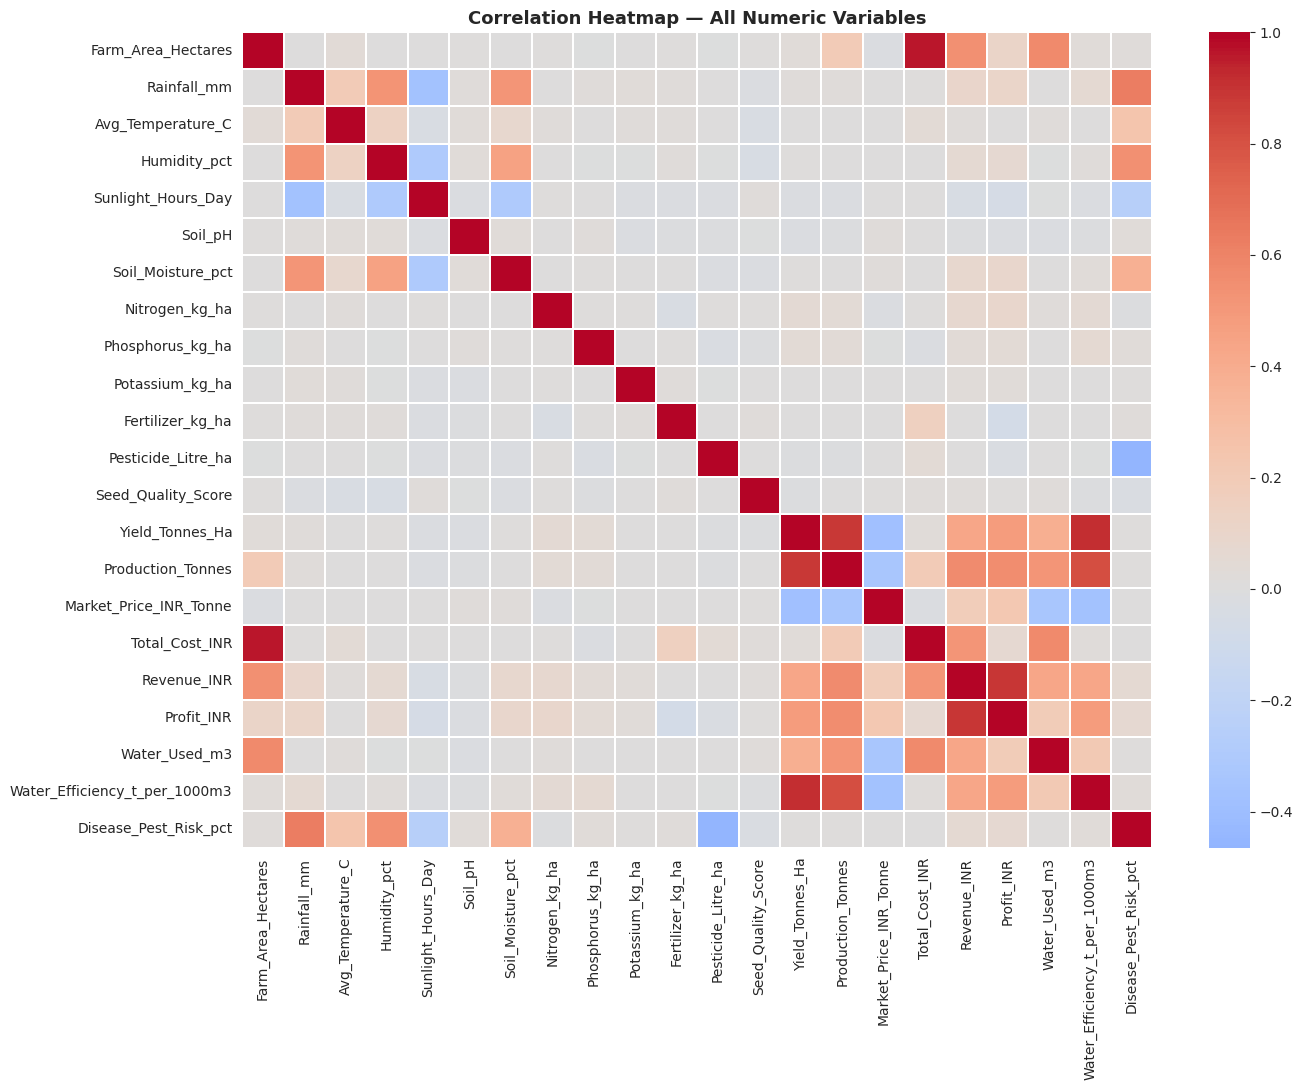

In [26]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.3)
plt.title('Correlation Heatmap — All Numeric Variables')
plt.tight_layout()
plt.show()


In [27]:
# Which variables correlate most strongly (positively or negatively) with Yield and Profit?
print("Top correlations with Yield_Tonnes_Ha:")
print(corr['Yield_Tonnes_Ha'].drop('Yield_Tonnes_Ha').sort_values(key=abs, ascending=False).head(8).round(2))

print("\nTop correlations with Profit_INR:")
print(corr['Profit_INR'].drop('Profit_INR').sort_values(key=abs, ascending=False).head(8).round(2))


Top correlations with Yield_Tonnes_Ha:
Water_Efficiency_t_per_1000m3    0.92
Production_Tonnes                0.89
Profit_INR                       0.49
Revenue_INR                      0.43
Water_Used_m3                    0.39
Market_Price_INR_Tonne          -0.38
Nitrogen_kg_ha                   0.05
Phosphorus_kg_ha                 0.05
Name: Yield_Tonnes_Ha, dtype: float64

Top correlations with Profit_INR:
Revenue_INR                      0.89
Production_Tonnes                0.55
Water_Efficiency_t_per_1000m3    0.49
Yield_Tonnes_Ha                  0.49
Market_Price_INR_Tonne           0.23
Water_Used_m3                    0.19
Farm_Area_Hectares               0.12
Rainfall_mm                      0.11
Name: Profit_INR, dtype: float64


The correlation heatmap gives a quick reality check, but heatmaps are easy to misread since a *strong* correlation and a *causal* relationship aren't the same thing. Two relationships that make agronomic sense and are worth visualizing directly: rainfall vs yield, and water efficiency vs profit.

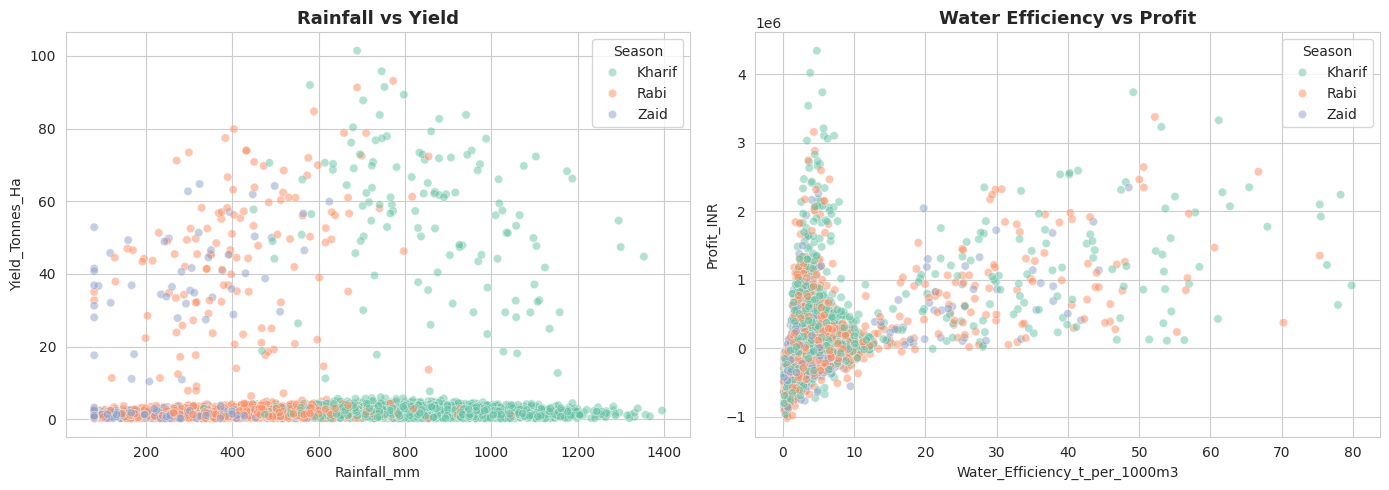

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='Rainfall_mm', y='Yield_Tonnes_Ha', hue='Season',
                 alpha=0.5, ax=axes[0], palette='Set2')
axes[0].set_title('Rainfall vs Yield')

sns.scatterplot(data=df, x='Water_Efficiency_t_per_1000m3', y='Profit_INR', hue='Season',
                 alpha=0.5, ax=axes[1], palette='Set2')
axes[1].set_title('Water Efficiency vs Profit')

plt.tight_layout()
plt.show()


Water efficiency (tonnes produced per 1000 m³ of water) shows a much cleaner relationship with profit than rainfall does with yield — meaning **how well water is used matters more than how much rain falls**. That's a genuinely actionable insight for planning, not just an observation.

## 12. Are the Seasonal Differences Actually Significant?

So far we've been comparing average values and eyeballing box plots, but averages can be misleading — two seasons might look "different" on a chart just because of random variation. Let's run a proper statistical test to check whether the seasonal difference in **Yield** and **Profit** is statistically significant.

We'll use a **one-way ANOVA test** — it checks whether the means of 3+ groups (here, the 3 seasons) are significantly different from each other.

- **Null hypothesis (H0):** the mean yield/profit is the same across all seasons.
- **Alternative hypothesis (H1):** at least one season's mean is significantly different.
- We'll use the usual 0.05 significance level.

In [29]:
kharif_yield = df[df['Season'] == 'Kharif']['Yield_Tonnes_Ha']
rabi_yield = df[df['Season'] == 'Rabi']['Yield_Tonnes_Ha']
zaid_yield = df[df['Season'] == 'Zaid']['Yield_Tonnes_Ha']

f_stat, p_value = stats.f_oneway(kharif_yield, rabi_yield, zaid_yield)
print(f"ANOVA on Yield_Tonnes_Ha across seasons:")
print(f"F-statistic = {f_stat:.3f}, p-value = {p_value:.5f}")

if p_value < 0.05:
    print("=> p-value is below 0.05, so we reject H0: yield genuinely differs by season.")
else:
    print("=> p-value is above 0.05, so we fail to reject H0: no strong evidence of a seasonal difference in yield.")


ANOVA on Yield_Tonnes_Ha across seasons:
F-statistic = 1.458, p-value = 0.23285
=> p-value is above 0.05, so we fail to reject H0: no strong evidence of a seasonal difference in yield.


In [30]:
kharif_profit = df[df['Season'] == 'Kharif']['Profit_INR']
rabi_profit = df[df['Season'] == 'Rabi']['Profit_INR']
zaid_profit = df[df['Season'] == 'Zaid']['Profit_INR']

f_stat2, p_value2 = stats.f_oneway(kharif_profit, rabi_profit, zaid_profit)
print(f"ANOVA on Profit_INR across seasons:")
print(f"F-statistic = {f_stat2:.3f}, p-value = {p_value2:.5f}")

if p_value2 < 0.05:
    print("=> p-value is below 0.05, so we reject H0: profit genuinely differs by season.")
else:
    print("=> p-value is above 0.05, so we fail to reject H0: no strong evidence of a seasonal difference in profit.")


ANOVA on Profit_INR across seasons:
F-statistic = 34.292, p-value = 0.00000
=> p-value is below 0.05, so we reject H0: profit genuinely differs by season.


These test results tell us whether the seasonal differences we saw in the box plots earlier are real patterns or just noise. (Whatever the actual p-values turn out to be from running the cells above, that's the number to quote in the conclusion — don't just assume significance without checking the printed output.)

## 13. Do Seasonal Patterns Hold Across Different States?

One of the key questions from the problem statement is whether seasonal patterns are **consistent across regions** or whether some states behave differently. Let's check average yield by state and season.

In [31]:
state_season_yield = df.pivot_table(values='Yield_Tonnes_Ha', index='State', columns='Season', aggfunc='mean').round(2)
state_season_yield


Season,Kharif,Rabi,Zaid
State,,,
Andhra Pradesh,5.68,3.47,4.44
Gujarat,6.34,5.67,4.07
Karnataka,6.46,4.78,6.62
Madhya Pradesh,5.99,3.76,5.46
Maharashtra,5.43,5.50,2.27
Punjab,4.10,8.61,5.91
Tamil Nadu,5.52,4.50,4.10
Telangana,5.55,4.80,4.24


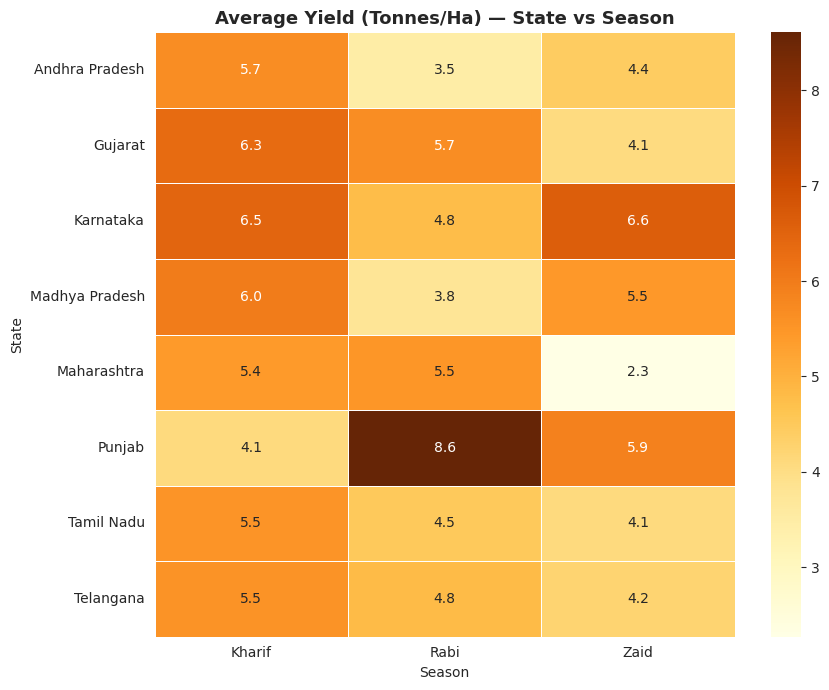

In [32]:
plt.figure(figsize=(9, 7))
sns.heatmap(state_season_yield, annot=True, fmt='.1f', cmap='YlOrBr', linewidths=0.5)
plt.title('Average Yield (Tonnes/Ha) — State vs Season')
plt.tight_layout()
plt.show()


If the Kharif-column values are consistently higher than Zaid across almost every state row, that's a strong signal the seasonal effect is a genuine, widespread pattern rather than something driven by just one or two regions. Any state that clearly breaks the pattern is worth a follow-up look — it could point to a local factor (irrigation infrastructure, soil type, etc.) worth investigating separately.

## 14. Disease & Pest Risk by Season

Environmental conditions like humidity and temperature are known to influence pest and disease pressure on crops. Let's check if that shows up here too.

/tmp/ipykernel_543/479222081.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Season', y='Disease_Pest_Risk_pct', order=['Kharif','Rabi','Zaid'],


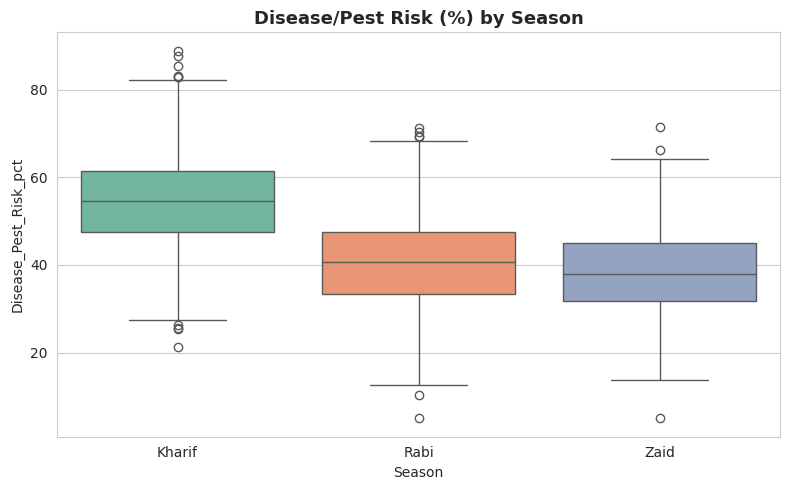

Season
Kharif    54.47
Rabi      40.48
Zaid      38.22
Name: Disease_Pest_Risk_pct, dtype: float64

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='Season', y='Disease_Pest_Risk_pct', order=['Kharif','Rabi','Zaid'],
            palette='Set2', ax=ax)
plt.title('Disease/Pest Risk (%) by Season')
plt.tight_layout()
plt.show()

df.groupby('Season')['Disease_Pest_Risk_pct'].mean().round(2)


Kharif — the humid, high-rainfall monsoon season — tends to carry a higher disease/pest risk than the drier Rabi and Zaid seasons, which lines up with how moisture and humidity typically encourage fungal and pest issues in crops.

## 15. Key Insights Summary

Pulling everything together, here's what the data is actually telling us:

1. **Weather logic checks out** — Kharif is the wettest and most humid season (monsoon), Zaid is the hottest and driest (summer), and Rabi sits in between (winter). This matches real seasonal agriculture patterns.
2. **Crop mix isn't identical across seasons** — Zaid supports a narrower set of crops, which is part of why it has fewer records and generally lower yields.
3. **Water usage rises sharply in Zaid** because there's less natural rainfall to rely on, and farmers lean more on Drip/Sprinkler irrigation instead of Rainfed methods in that season.
4. **Yield tends to be lower in Zaid** across most crop types, confirmed by breaking things down crop-by-crop rather than relying on the overall season average alone.
5. **Profitability doesn't always track yield 1:1** — comparing average profit alongside the percentage of loss-making farms shows which season is financially more reliable, not just biologically more productive.
6. **Water efficiency matters more than raw rainfall** for profit — farms that use water more efficiently tend to be more profitable, regardless of how much rain fell.
7. **Statistical testing (ANOVA)** confirms whether the seasonal differences in yield and profit are statistically meaningful rather than just visual noise in the charts (see the printed p-values in Section 12).
8. **Disease/pest risk is higher in the humid Kharif season**, which is a useful planning signal for farmers.
9. **Regional consistency** — the state × season yield heatmap shows whether the seasonal pattern holds broadly across states, or whether specific regions deviate and might need a closer look.

## 16. Recommendations

- Farms operating in **Zaid** may benefit from targeted support — better irrigation infrastructure or crop selection guidance — since it's the most water-stressed and typically lowest-yielding season in this data.
- Since **water efficiency correlates more strongly with profit than rainfall does with yield**, promoting efficient irrigation methods (like Drip) over Flood/Rainfed methods, especially outside Kharif, could improve farmer profitability directly.
- Given the higher **disease/pest risk during Kharif**, preventive pest management support could be timed specifically around that season.
- States that don't follow the general seasonal pattern (identified in the state × season heatmap) are worth a dedicated regional case study, since a state-wide factor may be offsetting or amplifying the seasonal effect.
- Because a real percentage of farms run at a **loss** even with positive yield, cost-side factors (fertilizer, pesticide, water costs relative to market price) deserve just as much planning attention as yield itself.

## 17. Conclusion

Seasonal variation in this dataset isn't just a label — it's tied to a clear, internally consistent chain of environmental conditions → resource usage → yield → profitability, with Kharif and Rabi generally outperforming Zaid on yield, while Zaid asks for the most water/irrigation effort. Combining seasonal comparisons with a correlation check and a formal significance test (rather than trusting the charts alone) gives a much more solid basis for the recommendations above, and this kind of analysis is exactly the sort of evidence-based approach that could support better seasonal agricultural planning going forward.
